# Seasonal Agriculture Performance Analysis
**VOIS AICTE Data Analytics Major Project**

How do the three Indian cropping seasons - **Kharif** (monsoon, Jun-Oct), **Rabi** (winter, Nov-Apr) and **Zaid** (summer, Mar-Jun) - differ in yield, profitability and resource use, and which factors actually drive yield?

The reusable logic lives in the `agri_analysis` package, so this notebook, `scripts/run_analysis.py` and the Streamlit dashboard all produce the same numbers. Every number quoted in the text below is computed in the cell above it.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

%matplotlib inline
import pandas as pd
from IPython.display import Markdown, display

from agri_analysis import analysis as A, plots
from agri_analysis.data import load_data, clean_data, validate_data

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 40)

raw = load_data()
df = clean_data(raw)
print("Raw shape:", raw.shape)
raw.head()

Raw shape: (4000, 28)


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.40,24.30,69.10,5.80,7.14,32.80,75.80,61.30,91.00,Drip,242.70,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.49,55.30
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.40,25.70,78.40,5.10,5.20,32.00,82.10,35.40,121.80,Flood,271.40,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.40,49.90
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.60,23.90,56.40,10.30,5.82,8.10,118.50,51.50,117.90,Drip,162.60,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.98,33.70
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.20,29.70,65.20,6.30,5.98,23.70,138.60,55.60,115.50,Rainfed,182.20,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.16,50.60
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.60,34.10,55.20,6.50,6.90,29.30,124.10,69.00,121.40,Flood,244.90,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.83,32.30


## 1. Dataset understanding and quality checks

4,000 farm-season records with 28 columns: location (state, district), crop and season, weather and soil, inputs (fertiliser, pesticide, seed quality, irrigation method) and outcomes (yield, production, price, cost, revenue, profit, water use and efficiency, disease/pest risk).

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [3]:
A.data_overview(df)

,Item,Value
0,Records,4000
1,States,8
2,Districts,10
3,Crops,8
4,Seasons,3
5,Irrigation methods,4
6,Missing Rainfall_mm,48
7,Missing Soil_Moisture_pct,40
8,Yield values recovered from Production / Area,32
9,Duplicate Farm_IDs,0


The derived columns obey exact accounting identities (deviations below are just CSV rounding). That means the 32 missing yields can be **recovered exactly** as `Production / Area` instead of being dropped or filled with an average. Missing rainfall (48) and soil moisture (40) cannot be recovered, so they are left blank and excluded pairwise.

In [4]:
validate_data(raw)

,Check,Rows_Checked,Max_Abs_Deviation
0,Production = Yield x Area,3968,0.01
1,Revenue = Production x Price,4000,0.50
2,Profit = Revenue - Cost,4000,0.00
3,Water efficiency = Production / Water x 1000,4000,0.00


In [5]:
raw.describe().T

,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,"4,000.00",7.89,4.22,0.50,4.26,7.89,11.65,15.00
Rainfall_mm,"3,952.00",601.15,288.93,80.00,370.20,582.00,834.95,"1,395.20"
Avg_Temperature_C,"4,000.00",26.82,3.82,16.20,23.90,26.90,29.60,39.70
Humidity_pct,"4,000.00",63.21,11.96,25.00,54.77,63.00,71.90,95.00
Sunlight_Hours_Day,"4,000.00",7.32,1.12,3.50,6.60,7.30,8.10,11.00
Soil_pH,"4,000.00",6.70,0.64,5.20,6.26,6.69,7.14,8.40
Soil_Moisture_pct,"3,960.00",26.51,6.71,8.00,21.70,26.40,31.30,47.00
Nitrogen_kg_ha,"4,000.00",120.25,31.22,40.00,98.50,120.10,141.22,220.00
Phosphorus_kg_ha,"4,000.00",57.78,17.02,15.00,46.20,57.50,69.40,120.00
Potassium_kg_ha,"4,000.00",104.76,27.74,30.00,86.20,105.10,123.60,200.00


### Why raw yields cannot be compared across crops

Sugarcane yields about 48 t/ha; every other crop yields 1-3 t/ha. Averaging raw yield across crops therefore mostly measures *how much sugarcane* a group contains. The analysis uses a **yield index** - a farm's yield divided by the median yield of the same crop (1.0 = typical) - and medians, which are robust to the long tail.

> Note: the dataset appears to be synthetic/simulated - districts are not tied to their real states (e.g. *Rajkot* appears under every state) and wheat appears in Kharif. Findings describe this dataset, not Indian agriculture as a whole.

In [6]:
A.crop_summary(df)[["Farms", "Median_Yield_Tonnes_Ha", "Avg_Yield_Tonnes_Ha", "Median_Price_INR_Tonne"]]

,Farms,Median_Yield_Tonnes_Ha,Avg_Yield_Tonnes_Ha,Median_Price_INR_Tonne
Crop,,,,
Sugarcane,305,48.03,46.93,"3,488.00"
Chilli,412,1.56,1.54,"102,995.00"
Cotton,508,1.24,1.22,"68,191.50"
Groundnut,424,1.40,1.32,"56,325.50"
Pulses,496,0.94,0.92,"71,096.50"
Maize,551,2.85,2.71,"20,979.00"
Rice,690,2.46,2.44,"22,044.50"
Wheat,614,2.21,2.11,"23,853.50"


## 2. Seasonal performance

In [7]:
A.season_summary(df)

,Farms,Median_Yield_Index,Avg_Yield_Tonnes_Ha,Total_Production_Tonnes,Avg_Revenue_INR,Avg_Cost_INR,Avg_Profit_INR,Median_Profit_per_Ha,Pct_Profitable,Median_Rainfall_mm,Median_Pest_Risk_pct,Avg_Water_Efficiency
Season,,,,,,,,,,,,
Kharif,1779,1.13,5.63,"82,387.61","710,719.06","531,804.41","178,914.65","8,340.45",57.79,854.75,54.50,5.89
Rabi,1627,0.97,5.09,"67,498.88","601,526.05","513,836.58","87,689.47",-894.33,48.86,430.30,40.60,5.19
Zaid,594,0.79,4.63,"23,098.35","519,171.90","543,976.73","-24,804.82","-13,760.26",35.52,283.30,37.90,4.41


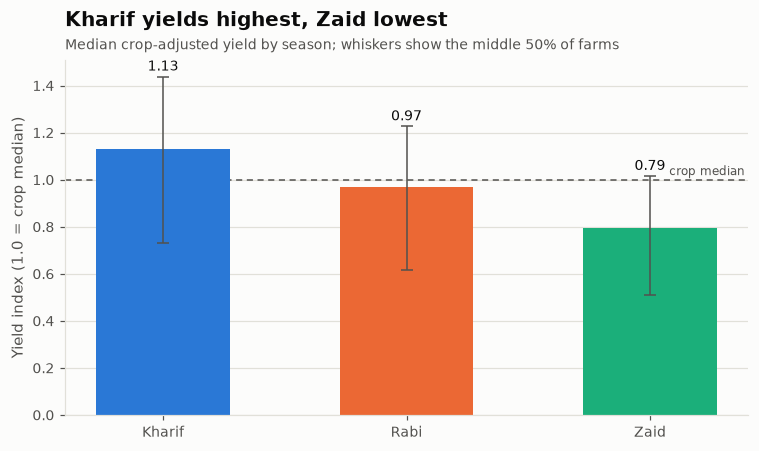

In [8]:
plots.season_yield_index(df);

In [9]:
A.seasonal_yield_change(df)

,Kharif_t_ha,Rabi_t_ha,Zaid_t_ha,Rabi_vs_Kharif_pct,Zaid_vs_Kharif_pct
Crop,,,,,
Pulses,1.09,0.90,0.66,-17.43,-39.91
Cotton,1.44,1.21,0.95,-15.97,-33.68
Rice,2.88,2.38,1.94,-17.36,-32.81
Sugarcane,56.65,45.46,38.78,-19.75,-31.54
Chilli,1.77,1.56,1.23,-11.86,-30.23
Groundnut,1.52,1.30,1.10,-14.47,-27.96
Maize,3.12,2.82,2.25,-9.62,-27.72
Wheat,2.36,2.22,1.84,-5.93,-22.03


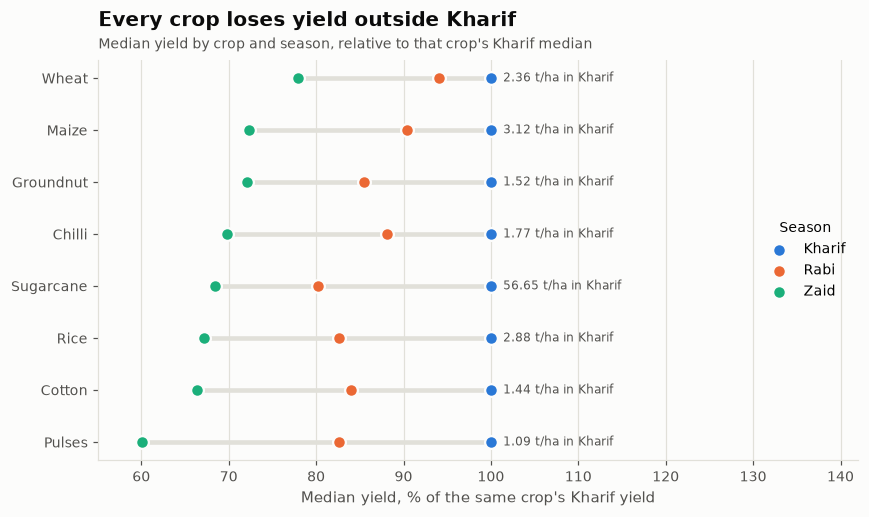

In [10]:
plots.crop_season_yield(df);

## 3. Crop profitability

Profit is compared **per hectare**, because farm size (0.5-15 ha) would otherwise dominate total profit.

In [11]:
A.crop_summary(df)[["Farms", "Median_Profit_per_Ha", "Median_Profit_Margin", "Pct_Profitable", "Avg_Profit_INR"]]

,Farms,Median_Profit_per_Ha,Median_Profit_Margin,Pct_Profitable,Avg_Profit_INR
Crop,,,,,
Sugarcane,305,"99,569.50",1.41,88.52,"817,187.99"
Chilli,412,"90,245.45",1.34,82.04,"750,878.34"
Cotton,508,"16,070.90",0.23,65.35,"124,546.92"
Groundnut,424,"9,781.48",0.14,59.20,"44,858.12"
Pulses,496,230.97,0.00,50.81,"-4,238.05"
Maize,551,"-10,437.89",-0.15,36.30,"-83,978.33"
Rice,690,"-13,158.57",-0.19,33.62,"-102,213.50"
Wheat,614,"-14,979.22",-0.23,25.90,"-123,398.34"


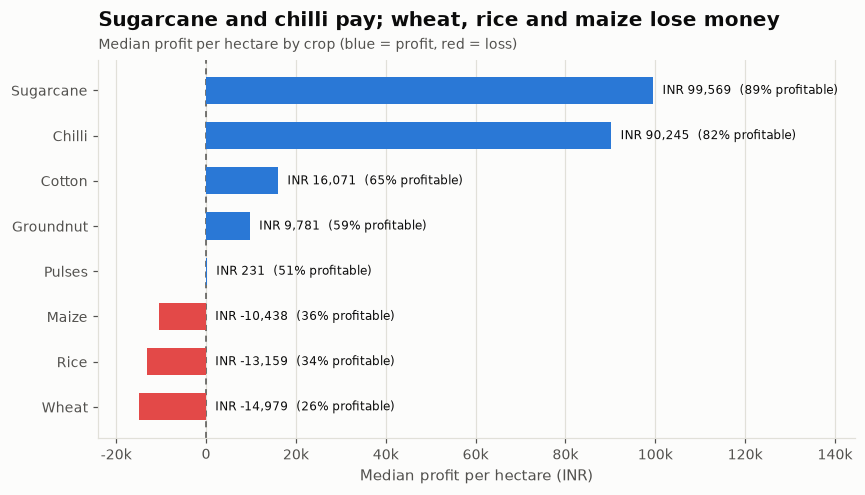

In [12]:
plots.crop_profit_per_ha(df);

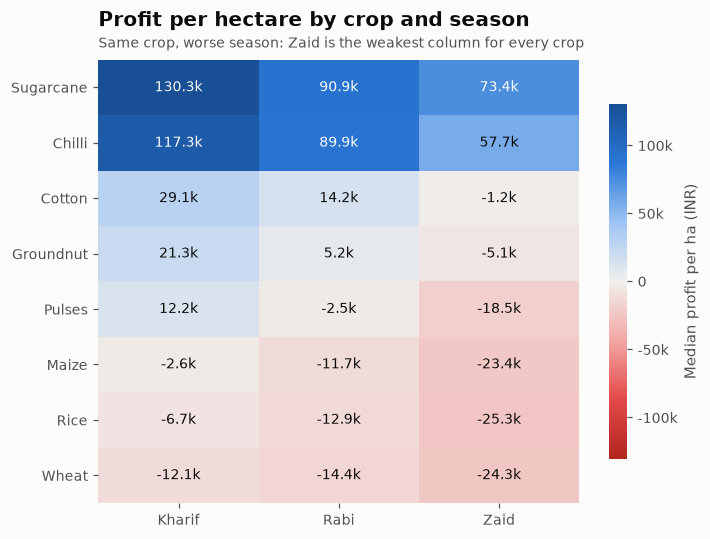

In [13]:
plots.crop_season_profit_heatmap(df);

## 4. Irrigation and water use

Water use is also made crop-comparable: `Water_Index` = water per hectare divided by the median for the same crop.

In [14]:
A.irrigation_summary(df)

,Farms,Median_Yield_Index,Median_Water_Index,Median_Water_m3_per_Ha,Avg_Water_Efficiency,Median_Profit_per_Ha,Pct_Profitable
Irrigation_Method,,,,,,,
Drip,915,1.12,0.92,529.84,6.27,"11,176.94",59.78
Sprinkler,734,1.02,1.05,589.87,4.67,"1,494.28",51.91
Flood,1310,0.98,1.35,772.50,3.44,"-2,185.92",47.18
Rainfed,1041,0.93,0.58,329.25,7.56,"-2,492.15",46.88


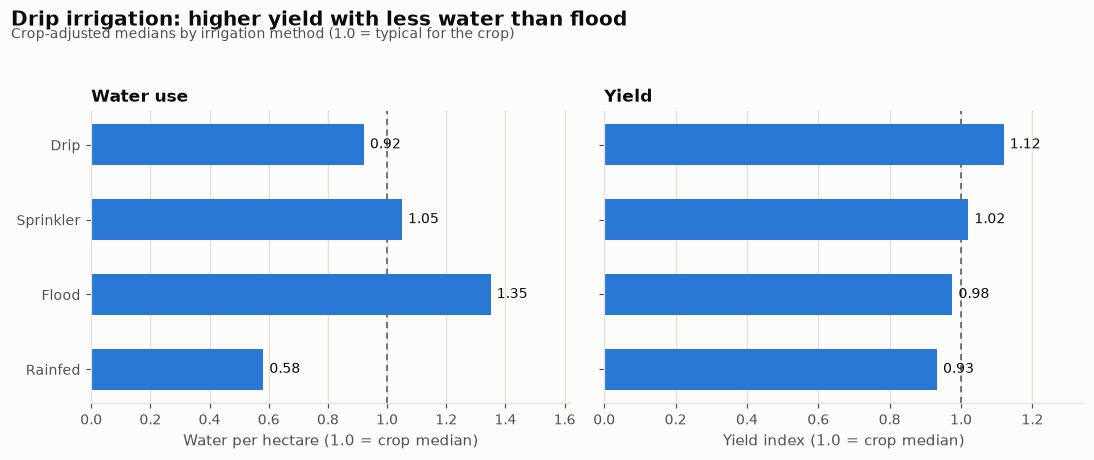

In [15]:
plots.irrigation_comparison(df);

## 5. Weather, soil, inputs and pest risk

Only genuine *inputs* are tested as yield drivers. Production, revenue, profit and water efficiency are computed from yield, so their correlation with it is true by construction (the first version of this project reported water efficiency as the "top driver" at 0.92 for exactly that reason).

In [16]:
A.yield_drivers(df)

,Spearman_vs_Yield_Index,Pearson_vs_Raw_Yield,N
Variable,,,
Rainfall_mm,0.24,0.03,3952
Soil_Moisture_pct,0.18,0.01,3960
Humidity_pct,0.16,0.01,4000
Disease_Pest_Risk_pct,0.14,0.01,4000
Sunlight_Hours_Day,-0.11,-0.02,4000
Nitrogen_kg_ha,0.11,0.05,4000
Phosphorus_kg_ha,0.06,0.05,4000
Potassium_kg_ha,0.03,0.01,4000
Farm_Area_Hectares,0.02,0.03,4000


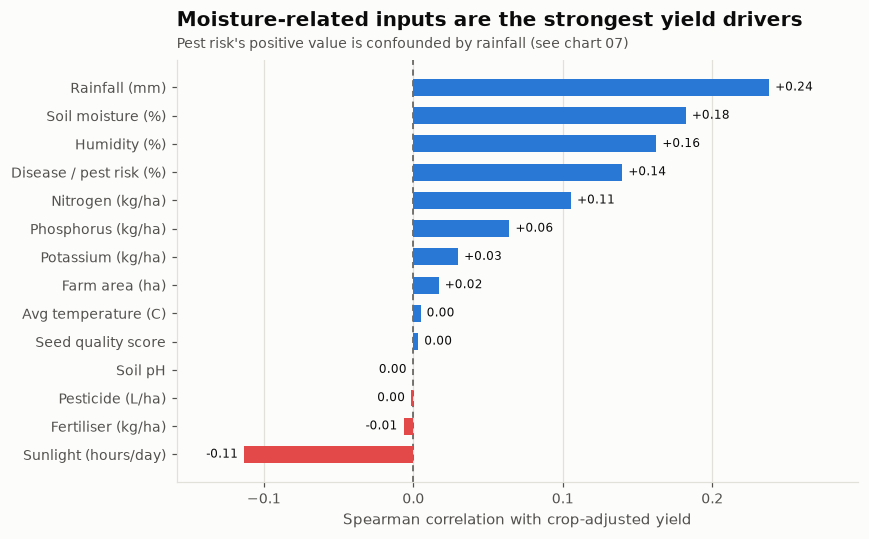

In [17]:
plots.yield_drivers(df);

In [18]:
A.rainfall_response(df)

,Farms,Median_Yield_Index,Q1_Yield_Index,Q3_Yield_Index,Median_Pest_Risk_pct
Rainfall_Band,,,,,
< 350 mm,890,0.79,0.50,1.00,36.55
350-550 mm,945,0.99,0.65,1.23,41.20
550-850 mm,1194,1.21,0.79,1.50,49.60
> 850 mm,923,1.05,0.68,1.32,56.60


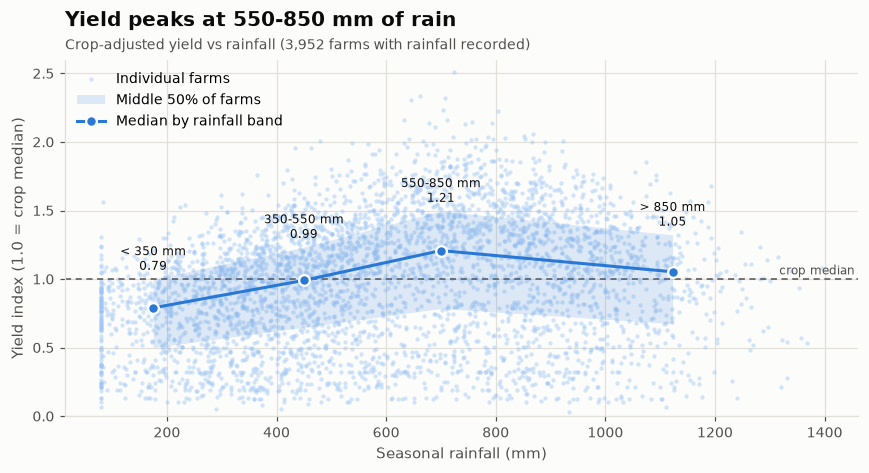

In [19]:
plots.rainfall_response(df);

Pest risk shows a *positive* pooled correlation with yield. Pest risk is strongly tied to rainfall and humidity, which also raise yield, so the pooled number is confounded. Holding rainfall fixed - and computing a partial correlation that controls for rainfall, humidity and soil moisture - removes the effect:

In [20]:
print("Pooled Spearman (pest risk vs yield index):", round(A.spearman(df["Disease_Pest_Risk_pct"], df["Yield_Index"]), 3))
print("Partial correlation, controlling for moisture:", round(A.pest_partial_correlation(df), 3))
A.pest_risk_by_rainfall(df)

Pooled Spearman (pest risk vs yield index): 0.14
Partial correlation, controlling for moisture: -0.03


Rainfall_Band,< 350 mm,350-550 mm,550-850 mm,> 850 mm
Pest_Band,,,,
< 30%,0.77,0.94,1.11,NaN
30-40%,0.81,1.03,1.10,1.18
40-50%,0.77,0.98,1.24,1.12
50-60%,0.82,1.02,1.23,1.07
> 60%,NaN,0.89,1.24,1.00


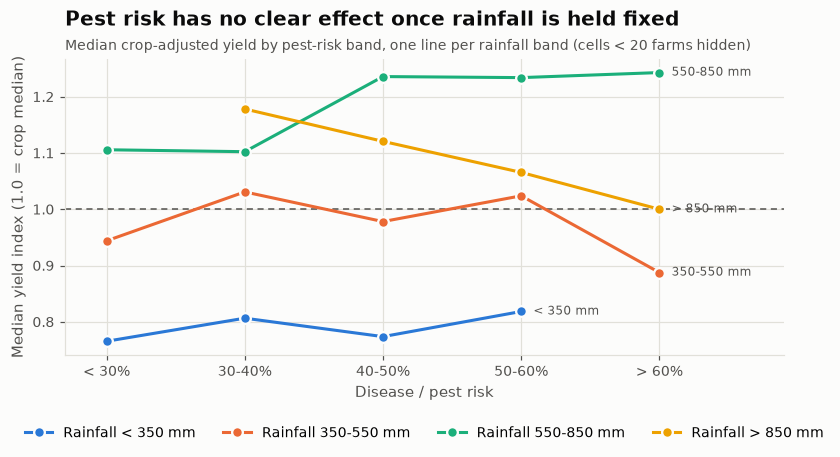

In [21]:
plots.pest_risk_effect(df);

## 6. State comparison

In [22]:
A.state_summary(df)

,Farms,Median_Yield_Index,Median_Profit_per_Ha,Pct_Profitable
State,,,,
Telangana,516,1.05,"3,333.68",54.84
Punjab,484,1.01,"2,819.42",52.27
Gujarat,488,1.00,778.69,50.61
Madhya Pradesh,497,1.00,-916.89,48.89
Tamil Nadu,485,1.00,-221.17,49.28
Maharashtra,512,1.00,-57.83,50.00
Karnataka,489,0.98,"2,420.40",52.56
Andhra Pradesh,529,0.98,"-1,156.82",48.39


## 7. Key findings

Generated from the data by `agri_analysis.analysis.key_findings`, so they update automatically if the dataset changes.

In [23]:
display(Markdown("\n".join(f"{i}. {f}" for i, f in enumerate(A.key_findings(df), 1))))

1. Season is the clearest yield signal: crop-adjusted median yield is 1.13 in Kharif, 0.97 in Rabi and 0.79 in Zaid (1.00 = typical for the crop). All 8 crops follow the same Kharif > Rabi > Zaid order; Zaid yields are 22-40% below Kharif depending on the crop.
2. Profitability follows the seasons: 58% of Kharif farms, 49% of Rabi farms and 36% of Zaid farms made a profit. Average cost is similar in every season and a crop's market price varies by at most 7% between seasons, so the gap comes from yield, not price.
3. Crop choice matters more than any input: Sugarcane and Chilli earn a median INR 99,569 and INR 90,245 profit per hectare, while Maize, Rice, Wheat lose money at the median (only 26-36% of those farms are profitable).
4. Drip irrigation gives the best crop-adjusted yield (1.12) and uses 32% less water per hectare than flood irrigation, which is both the most common method (1,310 farms) and the thirstiest. Rain-fed plots use the least water but have the lowest yield index (0.93).
5. Rainfall has a sweet spot: the yield index peaks in the 550-850 mm band (1.21), is lowest in the < 350 mm band (0.79) and falls back on very wet plots. Rainfall is the strongest single numeric driver (Spearman 0.24).
6. Pest risk looks *positively* related to yield when pooled (Spearman 0.14) only because pest risk rises with rainfall and humidity. After controlling for rainfall, humidity and soil moisture the partial correlation is -0.03: in this dataset pest risk has no meaningful independent effect on yield.
7. Fertiliser, pesticide volume, seed quality, soil pH and temperature show almost no relationship with crop-adjusted yield (|Spearman| < 0.05 for each; 7 of 14 candidate inputs are below that threshold), and state-level differences are small (median yield index 0.98-1.05).
8. The headline correlations in the first version of this project (water efficiency 0.92 and production 0.89 with yield) were artefacts: both columns are calculated from yield and dominated by sugarcane. They are replaced here by the crop-adjusted driver analysis.

## 8. Recommendations

1. **Plan the highest-value crops for Kharif.** Every crop yields most in Kharif, and Kharif is the only season where most farms are profitable. Zaid should be reserved for crops that still clear their costs there (sugarcane, chilli).
2. **Re-examine cereal economics.** Wheat, rice and maize lose money at the median in every season in this dataset; the problem is low price per tonne relative to cost, not low yield. Cost control, better price realisation (procurement / MSP channels) or a shift toward cotton, groundnut, chilli or sugarcane where agronomically suitable would help.
3. **Move flood-irrigated plots to drip.** Drip delivers the highest crop-adjusted yield while using less water per hectare than flood irrigation, the most common method here.
4. **Manage soil moisture, especially in dry plots.** Rainfall, soil moisture and humidity are the only inputs with a material association with yield; plots under 350 mm of rain yield about 20% below their crop's median.
5. **Don't expect more fertiliser or pesticide alone to raise yields.** Neither shows a relationship with crop-adjusted yield in this data; spending there can be reviewed for cost savings.
6. **Treat these as hypotheses to test.** The analysis is observational and the dataset appears simulated; recommendations should be validated with field trials or real district-level data before acting on them.